# Zika Case Prediction

This is a supervised regression problem because the target variable, `cases`, is numeric.

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Used

The following datasets are used:

- `train.csv`: training data containing Zika cases
- `test.csv`: test data for Kaggle prediction
- `weather.csv`: daily weather data
- `dengue.csv`: dengue-related data
- `sample_submission.csv`: required Kaggle submission format

In [152]:
df_zika = pd.read_csv("orig/train.csv")
df_score = pd.read_csv("orig/test.csv")
df_weather = pd.read_csv("orig/weather.csv")
df_dengue = pd.read_csv("orig/dengue.csv")
df_submission = pd.read_csv("orig/sample_submission.csv")

In [153]:
print("Zika train:", df_zika.shape)
print("Test:", df_score.shape)
print("Weather:", df_weather.shape)
print("Dengue:", df_dengue.shape)
print("Sample submission:", df_submission.shape)

Zika train: (2138, 19)
Test: (572, 4)
Weather: (19018, 28)
Dengue: (3444, 10)
Sample submission: (572, 2)


## Initial Data Inspection

The datasets are inspected to understand their structure, data types, missing values, and the target variable.

In [154]:
df_zika.head()

,location,EW,EW_start_date,pop,cases,cases_est,cases_est_min,cases_est_max,p_rt1,p_inc100k,Sublocation,alert,id,model_version,tweet,Rt,receptivity,transmission,epidemic_threshold
0,A,201501,2015-01-04,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150119589,2023-08-20,0,0.0,0,0,0
1,A,201502,2015-01-11,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150219589,2023-08-20,0,0.0,0,0,0
2,A,201503,2015-01-18,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150319589,2023-08-20,0,0.0,0,0,0
3,A,201504,2015-01-25,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150419589,2023-08-20,0,0.0,0,0,0
4,A,201505,2015-02-01,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150519589,2023-08-20,0,0.0,0,0,0


In [155]:
df_zika.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2138 entries, 0 to 2137
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   location            2138 non-null   object 
 1   EW                  2138 non-null   int64  
 2   EW_start_date       2138 non-null   object 
 3   pop                 2138 non-null   int64  
 4   cases               2138 non-null   int64  
 5   cases_est           2138 non-null   float64
 6   cases_est_min       2138 non-null   int64  
 7   cases_est_max       2138 non-null   int64  
 8   p_rt1               2138 non-null   float64
 9   p_inc100k           2138 non-null   float64
 10  Sublocation         2138 non-null   int64  
 11  alert               2138 non-null   int64  
 12  id                  2138 non-null   int64  
 13  model_version       2138 non-null   object 
 14  tweet               2138 non-null   int64  
 15  Rt                  2138 non-null   float64
 16  recept

In [156]:
df_zika.isna().sum()

location              0
EW                    0
EW_start_date         0
pop                   0
cases                 0
cases_est             0
cases_est_min         0
cases_est_max         0
p_rt1                 0
p_inc100k             0
Sublocation           0
alert                 0
id                    0
model_version         0
tweet                 0
Rt                    0
receptivity           0
transmission          0
epidemic_threshold    0
dtype: int64

In [157]:
df_weather.head()

,location,date,temperature_2m_min,temperature_2m_max,temperature_2m_mean,apparent_temperature_min,apparent_temperature_max,apparent_temperature_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,precipitation_sum,precipitation_hours,rain_sum,showers_sum,precipitation_probability_min,precipitation_probability_max,precipitation_probability_mean,sunshine_duration,daylight_duration,shortwave_radiation_sum,cloud_cover_mean,dew_point_2m_min,dew_point_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,soil_moisture_0_to_7cm_mean,et0_fao_evapotranspiration
0,A,2015-01-04,21.036999,25.387000,22.459915,23.571250,29.486015,25.565351,14.587776,28.440000,137.459090,20.9,12.0,20.9,0.0,NaN,NaN,NaN,28601.842,48720.734,16.83,95.375000,20.137,21.237000,20.557833,89.229454,0.482583,3.162444
1,A,2015-01-05,20.087000,24.887000,22.007833,22.368402,27.663261,24.436419,14.565548,32.039997,112.944590,5.9,7.0,5.9,0.0,NaN,NaN,NaN,25460.375,48692.746,13.23,91.958336,19.437,21.036999,20.205751,89.896080,0.479417,2.586162
2,A,2015-01-06,19.987000,27.536999,22.649500,22.408318,32.885635,25.724691,11.966953,24.840000,74.577774,10.3,8.0,10.3,0.0,NaN,NaN,NaN,42821.530,48662.836,22.07,72.541664,19.337,20.887000,20.084915,86.232840,0.482833,4.246061
3,A,2015-01-07,19.987000,30.137000,24.416168,22.608006,35.066390,27.825201,11.090103,28.080000,7.339958,5.8,6.0,5.8,0.0,NaN,NaN,NaN,45272.984,48631.062,26.56,25.583334,18.887,21.137000,20.078665,78.654230,0.461167,5.410966
4,A,2015-01-08,19.687000,29.937000,24.536997,22.005758,34.985410,28.000359,9.178235,27.720000,332.425500,2.6,5.0,2.6,0.0,NaN,NaN,NaN,45250.953,48597.492,28.29,19.083334,18.837,21.087000,19.784918,76.666115,0.472167,5.735424


In [158]:
df_dengue.head()

,location,EW,EW_start_date,cases,p_rt1,p_inc100k,alert,Rt,transmission,epidemic_threshold
0,A,201501,2015-01-04,370,1.0,3.001972,2,3.434149,1,1
1,A,201502,2015-01-11,389,1.0,3.156127,3,2.371683,1,1
2,A,201503,2015-01-18,640,1.0,5.192600,3,2.166121,1,1
3,A,201504,2015-01-25,870,1.0,7.058690,3,1.933723,1,2
4,A,201505,2015-02-01,1498,1.0,12.153930,3,2.266027,1,2


## Data Cleaning

Date columns are converted into datetime format so that epidemiological weeks and weather dates can be aligned correctly.

In [159]:
for df in [df_zika, df_score, df_dengue]:
    df['EW_start_date'] = pd.to_datetime(df['EW_start_date'])

df_weather['date'] = pd.to_datetime(df_weather['date'])

## Fix Epidemiological Week Dates

A cleaning function is used to correct inconsistent 3-day and 11-day gaps.

In [160]:
def fix_ew_dates(df):
    df = df.sort_values(['location', 'EW_start_date']).copy()
    fixed_groups = []

    for location, group in df.groupby('location'):
        group = group.copy()

        for i in range(1, len(group)):
            previous_date = group.iloc[i - 1]['EW_start_date']
            current_date = group.iloc[i]['EW_start_date']

            if current_date - previous_date != pd.Timedelta(days=7):
                group.iloc[i, group.columns.get_loc('EW_start_date')] = previous_date + pd.Timedelta(days=7)

        fixed_groups.append(group)

    return pd.concat(fixed_groups).sort_index()

In [161]:
df_zika = fix_ew_dates(df_zika)
df_dengue = fix_ew_dates(df_dengue)
df_score = fix_ew_dates(df_score)

In [162]:
df_z = df_zika.sort_values(['location', 'EW_start_date'])

(df_z.groupby('location')['EW_start_date']
 .diff()
 .value_counts())

EW_start_date
7 days    2132
Name: count, dtype: int64

## Exploratory Data Analysis

Exploratory analysis is used to understand the target variable and identify useful patterns in the data.

In [163]:
df_zika['cases'].describe()

count    2138.000000
mean        5.395229
std        13.597583
min         0.000000
25%         0.000000
50%         1.000000
75%         5.000000
max       164.000000
Name: cases, dtype: float64

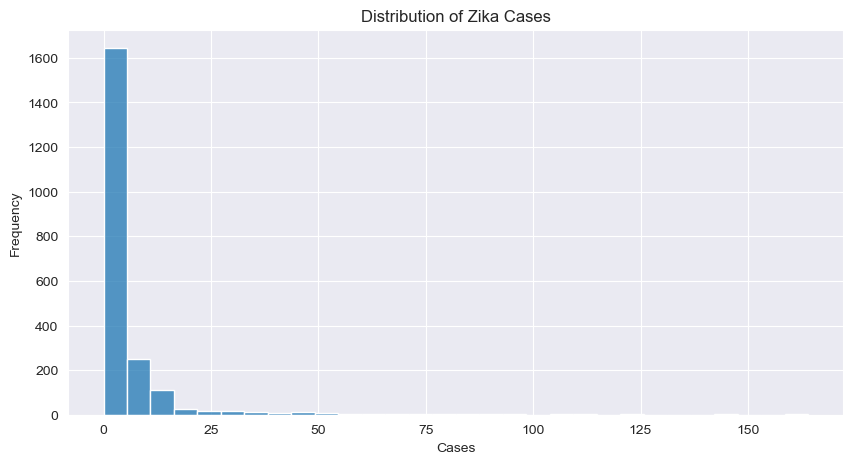

In [164]:
plt.figure(figsize=(10, 5))
sns.histplot(df_zika['cases'], bins=30)
plt.title("Distribution of Zika Cases")
plt.xlabel("Cases")
plt.ylabel("Frequency")
plt.show()

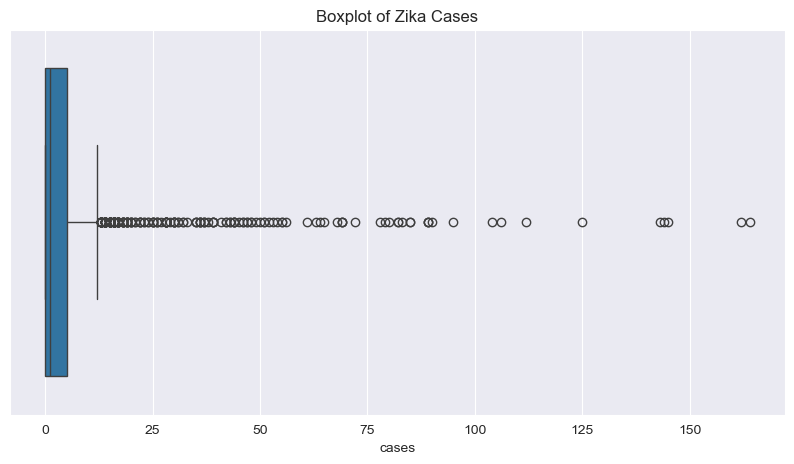

In [165]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df_zika['cases'])
plt.title("Boxplot of Zika Cases")
plt.show()

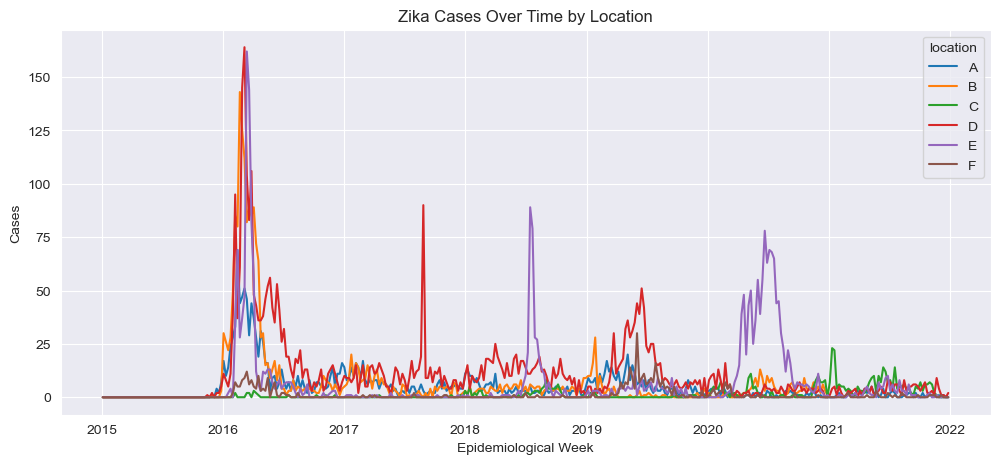

In [166]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df_zika, x='EW_start_date', y='cases', hue='location')
plt.title("Zika Cases Over Time by Location")
plt.xlabel("Epidemiological Week")
plt.ylabel("Cases")
plt.show()

## Align Daily Weather with Epidemiological Weeks

Weather data is recorded daily, while Zika cases are recorded weekly.  
Each daily weather row is matched to the nearest previous epidemiological week start date.

In [167]:
df_i = pd.concat((df_zika, df_score), ignore_index=True)

df_i = (
    df_i[['EW_start_date']]
    .drop_duplicates()
    .sort_values('EW_start_date')
)

df_w = df_weather.sort_values('date')

df_w = pd.merge_asof(
    df_w,
    df_i,
    left_on='date',
    right_on='EW_start_date',
    direction='backward'
)

df_w.head()

,location,date,temperature_2m_min,temperature_2m_max,temperature_2m_mean,apparent_temperature_min,apparent_temperature_max,apparent_temperature_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,precipitation_sum,precipitation_hours,rain_sum,showers_sum,precipitation_probability_min,precipitation_probability_max,precipitation_probability_mean,sunshine_duration,daylight_duration,shortwave_radiation_sum,cloud_cover_mean,dew_point_2m_min,dew_point_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,soil_moisture_0_to_7cm_mean,et0_fao_evapotranspiration,EW_start_date
0,A,2015-01-04,21.036999,25.3870,22.459915,23.571250,29.486015,25.565351,14.587776,28.440000,137.459090,20.9,12.0,20.9,0.0,NaN,NaN,NaN,28601.842,48720.734,16.83,95.375000,20.137000,21.2370,20.557833,89.229454,0.482583,3.162444,2015-01-04
1,B,2015-01-04,22.489000,29.5390,24.922335,27.178604,36.405045,30.250677,5.052841,23.400000,229.720170,7.9,13.0,7.9,0.0,NaN,NaN,NaN,36726.625,45663.184,18.59,85.125000,22.239000,24.7890,23.105667,90.521210,0.486708,3.744489,2015-01-04
2,C,2015-01-04,22.211000,25.0610,23.371420,26.686571,30.646660,28.331451,5.804825,14.759999,25.096127,8.1,12.0,8.1,0.0,NaN,NaN,NaN,17078.162,45181.380,8.42,94.625000,22.061000,23.7110,22.817247,96.779144,0.459292,1.699853,2015-01-04
3,D,2015-01-04,24.317501,32.1675,27.611246,29.854725,40.037487,33.372210,8.049845,23.039999,177.667050,0.4,1.0,0.4,0.0,NaN,NaN,NaN,34960.992,46870.098,22.31,87.041664,22.567501,24.7175,23.867500,81.221400,0.416917,4.755053,2015-01-04
4,E,2015-01-04,23.148000,27.6480,25.212580,26.405285,29.999668,28.058342,18.328207,36.360000,52.142280,7.1,17.0,7.1,0.0,NaN,NaN,NaN,29288.959,44677.453,12.43,74.958336,21.048000,22.4480,21.829252,82.090460,0.256917,2.908421,2015-01-04


## Weekly Weather Aggregation

Daily weather data is aggregated into weekly weather features so it can be merged with the weekly Zika data.

In [168]:
weather_cols = df_w.select_dtypes(include='number').columns.tolist()

df_weather_weekly = (
    df_w.groupby(['location', 'EW_start_date'])[weather_cols]
    .mean()
    .reset_index()
)

df_weather_weekly.head()

,location,EW_start_date,temperature_2m_min,temperature_2m_max,temperature_2m_mean,apparent_temperature_min,apparent_temperature_max,apparent_temperature_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,precipitation_sum,precipitation_hours,rain_sum,showers_sum,precipitation_probability_min,precipitation_probability_max,precipitation_probability_mean,sunshine_duration,daylight_duration,shortwave_radiation_sum,cloud_cover_mean,dew_point_2m_min,dew_point_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,soil_moisture_0_to_7cm_mean,et0_fao_evapotranspiration
0,A,2015-01-04,20.429857,28.579857,23.976880,23.078308,33.011426,27.194156,12.278599,29.159999,178.860006,6.857143,6.285714,6.857143,0.0,NaN,NaN,NaN,39694.695429,48627.462000,23.022857,50.690476,19.265571,21.465571,20.234917,81.237070,0.467274,4.650057
1,A,2015-01-11,22.015571,30.758429,25.772118,25.907393,36.196149,29.992573,11.857266,28.954285,156.725250,2.185714,3.428571,2.185714,0.0,NaN,NaN,NaN,44199.379857,48358.900429,26.032857,48.666667,19.215571,23.665571,21.551583,79.885719,0.407083,5.388690
2,A,2015-01-18,20.051286,28.394143,23.669440,22.421437,32.932097,26.361803,16.398022,34.199999,140.137516,1.600000,3.714286,1.600000,0.0,NaN,NaN,NaN,42864.636286,48020.476429,24.081429,60.428571,17.415571,21.979857,19.699798,80.764162,0.296524,4.823850
3,A,2015-01-25,20.044143,26.772714,23.017952,21.835466,29.609373,25.118796,18.622403,40.628569,289.356130,2.071429,5.571429,2.071429,0.0,NaN,NaN,NaN,30591.596186,47611.571714,18.948571,90.565477,18.465571,20.415571,19.419142,81.162148,0.438732,3.815835
4,A,2015-02-01,18.858428,25.315571,21.181643,20.966690,29.202483,23.585188,15.152506,35.691428,193.556619,8.714286,9.714286,8.714286,0.0,NaN,NaN,NaN,31507.407429,47147.465429,17.837143,80.797620,18.101286,20.215571,19.040570,88.201662,0.477649,3.385726


## Merge Weather Data

The weekly weather features are merged into the training and test datasets using `location` and `EW_start_date`.

In [169]:
train = df_zika.merge(
    df_weather_weekly,
    on=['location', 'EW_start_date'],
    how='left'
)

test = df_score.merge(
    df_weather_weekly,
    on=['location', 'EW_start_date'],
    how='left'
)

print(train.shape)
print(test.shape)

(2138, 45)
(572, 30)


## Merge Dengue Data

Dengue data is renamed before merging so that the same dengue feature names exist in both the training and test datasets.

In [170]:
dengue_features = df_dengue.rename(columns={
    'cases': 'dengue_cases',
    'p_rt1': 'dengue_p_rt1',
    'p_inc100k': 'dengue_p_inc100k',
    'alert': 'dengue_alert',
    'Rt': 'dengue_Rt',
    'transmission': 'dengue_transmission',
    'epidemic_threshold': 'dengue_epidemic_threshold'
})

In [171]:
dengue_features = dengue_features[
    [
        'location',
        'EW_start_date',
        'dengue_cases',
        'dengue_p_rt1',
        'dengue_p_inc100k',
        'dengue_alert',
        'dengue_Rt',
        'dengue_transmission',
        'dengue_epidemic_threshold'
    ]
]

In [172]:
train = train.merge(
    dengue_features,
    on=['location', 'EW_start_date'],
    how='left'
)

test = test.merge(
    dengue_features,
    on=['location', 'EW_start_date'],
    how='left'
)

print(train.shape)
print(test.shape)

(2138, 52)
(572, 37)


## Feature Engineering

Time-based and location-based features are created to help the model capture seasonal and geographical patterns.

In [173]:
for df in [train, test]:
    df['year'] = df['EW_start_date'].dt.year
    df['month'] = df['EW_start_date'].dt.month
    df['weekofyear'] = df['EW_start_date'].dt.isocalendar().week.astype(int)
    df['location_num'] = df['location'].astype('category').cat.codes

In [174]:
train.head()

,location,EW,EW_start_date,pop,cases,cases_est,cases_est_min,cases_est_max,p_rt1,p_inc100k,Sublocation,alert,id,model_version,tweet,Rt,receptivity,transmission,epidemic_threshold,temperature_2m_min,temperature_2m_max,temperature_2m_mean,apparent_temperature_min,apparent_temperature_max,apparent_temperature_mean,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,precipitation_sum,precipitation_hours,rain_sum,showers_sum,precipitation_probability_min,precipitation_probability_max,precipitation_probability_mean,sunshine_duration,daylight_duration,shortwave_radiation_sum,cloud_cover_mean,dew_point_2m_min,dew_point_2m_max,dew_point_2m_mean,relative_humidity_2m_mean,soil_moisture_0_to_7cm_mean,et0_fao_evapotranspiration,dengue_cases,dengue_p_rt1,dengue_p_inc100k,dengue_alert,dengue_Rt,dengue_transmission,dengue_epidemic_threshold,year,month,weekofyear,location_num
0,A,201501,2015-01-04,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150119589,2023-08-20,0,0.0,0,0,0,20.429857,28.579857,23.976880,23.078308,33.011426,27.194156,12.278599,29.159999,178.860006,6.857143,6.285714,6.857143,0.0,NaN,NaN,NaN,39694.695429,48627.462000,23.022857,50.690476,19.265571,21.465571,20.234917,81.237070,0.467274,4.650057,370,1.0,3.001972,2,3.434149,1,1,2015,1,1,0
1,A,201502,2015-01-11,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150219589,2023-08-20,0,0.0,0,0,0,22.015571,30.758429,25.772118,25.907393,36.196149,29.992573,11.857266,28.954285,156.725250,2.185714,3.428571,2.185714,0.0,NaN,NaN,NaN,44199.379857,48358.900429,26.032857,48.666667,19.215571,23.665571,21.551583,79.885719,0.407083,5.388690,389,1.0,3.156127,3,2.371683,1,1,2015,1,2,0
2,A,201503,2015-01-18,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150319589,2023-08-20,0,0.0,0,0,0,20.051286,28.394143,23.669440,22.421437,32.932097,26.361803,16.398022,34.199999,140.137516,1.600000,3.714286,1.600000,0.0,NaN,NaN,NaN,42864.636286,48020.476429,24.081429,60.428571,17.415571,21.979857,19.699798,80.764162,0.296524,4.823850,640,1.0,5.192600,3,2.166121,1,1,2015,1,3,0
3,A,201504,2015-01-25,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150419589,2023-08-20,0,0.0,0,0,0,20.044143,26.772714,23.017952,21.835466,29.609373,25.118796,18.622403,40.628569,289.356130,2.071429,5.571429,2.071429,0.0,NaN,NaN,NaN,30591.596186,47611.571714,18.948571,90.565477,18.465571,20.415571,19.419142,81.162148,0.438732,3.815835,870,1.0,7.058690,3,1.933723,1,2,2015,1,4,0
4,A,201505,2015-02-01,12325232,0,0.0,0,0,0.5,0.0,0,1,355030820150519589,2023-08-20,0,0.0,0,0,0,18.858428,25.315571,21.181643,20.966690,29.202483,23.585188,15.152506,35.691428,193.556619,8.714286,9.714286,8.714286,0.0,NaN,NaN,NaN,31507.407429,47147.465429,17.837143,80.797620,18.101286,20.215571,19.040570,88.201662,0.477649,3.385726,1498,1.0,12.153930,3,2.266027,1,2,2015,2,5,0


## Prepare Data for Modelling

Only columns available in both train and test are used.  
Numeric features are selected and missing values are filled using the training median.

In [175]:
target = 'cases'

drop_cols = [
    'cases',
    'EW_start_date',
    'location'
]

X = train.drop(columns=drop_cols, errors='ignore')
y = train[target]

X_test = test.drop(columns=['EW_start_date', 'location'], errors='ignore')

X = X.select_dtypes(include='number')
X_test = X_test.select_dtypes(include='number')

common_cols = X.columns.intersection(X_test.columns)

X = X[common_cols]
X_test = X_test[common_cols]

X = X.fillna(X.median())
X_test = X_test.fillna(X.median())

print("Train features:", X.shape)
print("Test features:", X_test.shape)
print("Features used:", list(X.columns))

Train features: (2138, 39)
Test features: (572, 39)
Features used: ['EW', 'pop', 'temperature_2m_min', 'temperature_2m_max', 'temperature_2m_mean', 'apparent_temperature_min', 'apparent_temperature_max', 'apparent_temperature_mean', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'precipitation_sum', 'precipitation_hours', 'rain_sum', 'showers_sum', 'precipitation_probability_min', 'precipitation_probability_max', 'precipitation_probability_mean', 'sunshine_duration', 'daylight_duration', 'shortwave_radiation_sum', 'cloud_cover_mean', 'dew_point_2m_min', 'dew_point_2m_max', 'dew_point_2m_mean', 'relative_humidity_2m_mean', 'soil_moisture_0_to_7cm_mean', 'et0_fao_evapotranspiration', 'dengue_cases', 'dengue_p_rt1', 'dengue_p_inc100k', 'dengue_alert', 'dengue_Rt', 'dengue_transmission', 'dengue_epidemic_threshold', 'year', 'month', 'weekofyear', 'location_num']


## Model Used

A Random Forest Regressor is used as the baseline model.  
It is suitable for tabular data and can model non-linear relationships.

In [176]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

## Validation

A validation split is used to estimate model performance before Kaggle submission.  
The model is trained on part of the training data and tested on unseen validation data using Mean Absolute Error (MAE).

In [177]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [178]:
val_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2
)

val_model.fit(X_train, y_train)

val_preds = val_model.predict(X_val)

mae = mean_absolute_error(y_val, val_preds)

print("Validation MAE:", mae)

Validation MAE: 3.1543500166327267


## Final Model Training

After validation, the final model is trained on the full training dataset to use all available labelled data before predicting the Kaggle test set.

In [179]:
model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2
)

model.fit(X, y)

,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## Feature Importance

Feature importance is used to understand which variables contributed most to the Random Forest model predictions.

In [180]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values('Importance', ascending=False)

importance.head(10)

,Feature,Importance
0,EW,0.146375
28,dengue_cases,0.118053
22,dew_point_2m_min,0.109492
2,temperature_2m_min,0.088803
30,dengue_p_inc100k,0.075627
38,location_num,0.056765
5,apparent_temperature_min,0.043585
31,dengue_alert,0.032805
8,wind_speed_10m_max,0.029661
29,dengue_p_rt1,0.025431


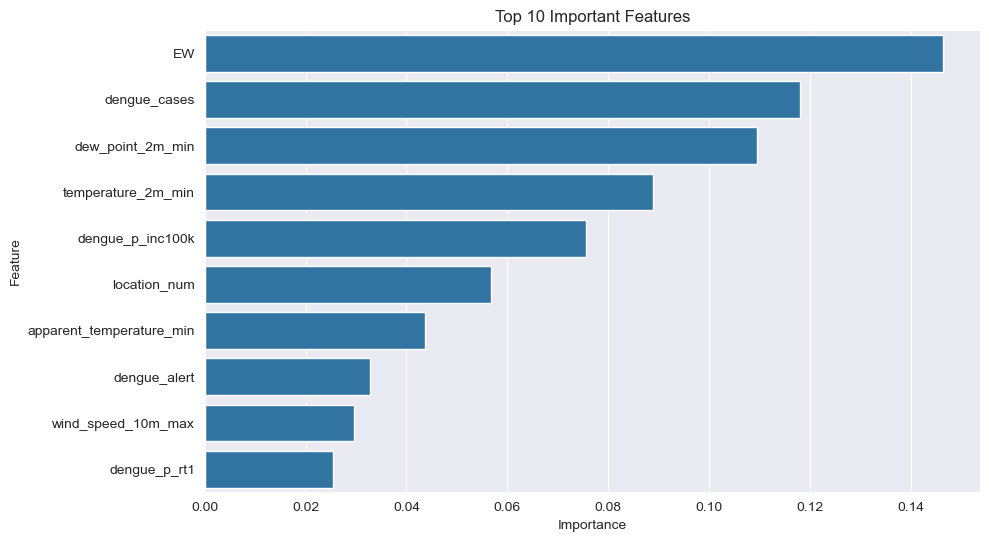

In [181]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.show()

## Final Submission

Predictions are generated for the Kaggle test dataset and saved in the required submission format.

In [182]:
preds = model.predict(X_test)

In [183]:
submission = df_submission.copy()
submission['cases'] = preds

submission.to_csv("output/submission.csv", index=False)

submission.head()

,ID,cases
0,A202201,4.963413
1,A202202,3.206218
2,A202203,1.851750
3,A202204,2.389861
4,A202205,5.164817
